In [1]:
import os
import random
import time
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import torch
from torch.utils.data import DataLoader, Subset
from sklearn.model_selection import train_test_split

from notebooks.util.data_preparing import (
    evaluate_results,
    evaluate_test_data,
    plot_confusion_matrix,
)

# 這個檔案需要和本 notebook 放在同一個資料夾
# 它包含 TabularParquetDataset + 原本 AE-ViT 架構
from transformer_AEViT_1D_parquet_tabular import (
    ViTAutoencoderConfig,
    build_model,
    pretrain_one_epoch,
    validate,
    TabularParquetDataset,
    SplitFolderNpyDataset,
    build_split_and_balance_dataset,
)

SPLIT_SEED = 42
SEEDS = [7, 17, 27, 37, 47]


def set_global_seed(seed: int):
    os.environ["PYTHONHASHSEED"] = str(seed)
    os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":16:8"
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True
    torch.use_deterministic_algorithms(True, warn_only=True)


def make_worker(seed_base: int):
    def _seed_worker(worker_id):
        s = seed_base + worker_id
        np.random.seed(s)
        random.seed(s)
    return _seed_worker


def _fmt_hms(seconds: float) -> str:
    m, s = divmod(int(seconds), 60)
    h, m = divmod(m, 60)
    return f"{h:02d}:{m:02d}:{s:02d}"


def load_state_dict_exact_or_matching(model, ckpt, cfg, allow_partial: bool = False):
    """
    預設要求 checkpoint 與目前 tabular AE-ViT input shape 完全相容。
    如果 allow_partial=True，則只載入 shape 相同的權重。
    """
    state_dict = ckpt["state_dict"] if isinstance(ckpt, dict) and "state_dict" in ckpt else ckpt

    if not allow_partial:
        model.load_state_dict(state_dict, strict=True)
        return

    model_dict = model.state_dict()
    matched = {}
    skipped = []

    for k, v in state_dict.items():
        if k in model_dict and tuple(model_dict[k].shape) == tuple(v.shape):
            matched[k] = v
        else:
            skipped.append(k)

    model_dict.update(matched)
    model.load_state_dict(model_dict, strict=False)

    print(f"[Partial Load] loaded matched tensors: {len(matched)}")
    print(f"[Partial Load] skipped unmatched tensors: {len(skipped)}")
    for k in skipped:
        print("  skipped:", k)


device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)
if torch.cuda.is_available():
    print("Using GPU:", torch.cuda.get_device_name(0))
else:
    print("No GPU found, using CPU")


# ============================================================
# Dataset settings
# ============================================================

# Use "parquet" for NF-UNSW-NB15-v3.parquet tabular data.
# Use "npy_split" only if you want to keep the original .npy folder behavior.
DATA_FORMAT = "parquet"       # "parquet" or "npy_split"

# -------------------------
# Parquet tabular settings
# -------------------------
PARQUET_PATH = "../data/New Data/NF-UNSW-NB15-v3.parquet"
# PARQUET_PATH = "../data/New Data/NF-CICIDS2018-v3.parquet"
LABEL_COL = "Label"
ATTACK_COL = "Attack"

# -------------------------
# Original npy fallback settings
# -------------------------
NPY_DATA_ROOT = "../data/New Data/NB15/feature_out_5/_MERGED_ALL_NPY"

# ============================================================
# Adjustable AE-ViT input shape
# ============================================================
# For NF-UNSW-NB15-v3.parquet:
#   47 numeric features + 1 zero padding = 48
#
# Recommended tabular setting:
#   INPUT_MODE="flat_1d"
#   PACKET_SHAPE=(1, 48)
#   PATCH_SIZE=4
#
# This keeps the AE-ViT architecture, but changes the input contract.
INPUT_MODE = "flat_1d"        # "flat_1d" or "packet_2d"
PACKET_SHAPE = (1, 48)
PATCH_SIZE = 4

TRAIN_TARGET_SIZE = 700000
MAX_TEST_SIZE_PER_CLASS = 10000

# 如果你想用舊的 (5,96) checkpoint 只載入 shape 相同的層，可以改 True。
# 但嚴謹的 tabular AE-ViT fine-tune 建議使用同 shape 預訓練 checkpoint，並保持 False。
ALLOW_PARTIAL_CHECKPOINT_LOAD = False


# ============================================================
# Build dataset
# ============================================================

if DATA_FORMAT == "parquet":
    full_ds = TabularParquetDataset(
        parquet_path=PARQUET_PATH,
        label_col=LABEL_COL,
        attack_col=ATTACK_COL,
        input_mode=INPUT_MODE,
        packet_shape=PACKET_SHAPE,
        scale=True,
        allow_truncate=False,
        max_rows=None,
    )

    train_subset, test_subset, benign_idx_train = build_split_and_balance_dataset(
        full_ds=full_ds,
        train_ds=None,
        test_ds=None,
        benign_name="benign",
        split_ratio=0.7,
        train_use_ratio=1.0,
        test_use_ratio=1.0,
        train_target_size=TRAIN_TARGET_SIZE,
        max_test_size_per_class=MAX_TEST_SIZE_PER_CLASS,
        seed=SPLIT_SEED,
    )

elif DATA_FORMAT == "npy_split":
    full_ds = SplitFolderNpyDataset(
        Path(NPY_DATA_ROOT),
        use_label_file=False,
        input_mode=INPUT_MODE,
        packet_shape=PACKET_SHAPE,
    )

    train_subset, test_subset, benign_idx_train = build_split_and_balance_dataset(
        full_ds=full_ds,
        train_ds=None,
        test_ds=None,
        benign_name="benign",
        split_ratio=0.7,
        train_use_ratio=1.0,
        test_use_ratio=1.0,
        train_target_size=TRAIN_TARGET_SIZE,
        max_test_size_per_class=MAX_TEST_SIZE_PER_CLASS,
        seed=SPLIT_SEED,
    )

else:
    raise ValueError(f"Unknown DATA_FORMAT: {DATA_FORMAT}")

print("train_subset:", len(train_subset))
print("test_subset:", len(test_subset))
print("benign_idx_train:", benign_idx_train)

Device: cuda
Using GPU: AMD Instinct MI300X
[ParquetDataset] Loading: /mlsteam/data/New Data/NF-UNSW-NB15-v3.parquet
[ParquetDataset] Loaded successfully
  Original parquet shape: (1177373, 49)
  Numeric feature dim: 47
  Target AE-ViT dim: 48
  Adjustment: padded 47 -> 48
  input_mode: flat_1d
  packet_shape: (1, 48)
  Label distribution:
    benign: 1085481
    attack: 91892
[Info] Test set is too large. Limit per class to 10000
[Warn] benign/attack counts in test region are imbalanced. Using balanced K=10000
--- 數據拆分報告 ---
原始總樣本數: 1177373
訓練區域總數: 824161
訓練區域中的良性樣本數: 759843
指定訓練集大小: 700000
最終訓練集大小: 700000
測試區域總數: 353212
平衡測試候選 benign 數: 10000
平衡測試候選 attack 數: 10000
實際使用測試比例: 1.00
最終測試集大小: 20000
benign_idx_val: 0
train_subset: 700000
test_subset: 20000
benign_idx_train: 0


In [2]:
# ============================================================
# Load pretrained tabular AE-ViT Optuna result
# ============================================================

shape_tag = f"{INPUT_MODE}_{PACKET_SHAPE[0]}x{PACKET_SHAPE[1]}_patch{PATCH_SIZE}"

# 預設對應 transformer_AEViT_1D_parquet_tabular.py 的輸出資料夾
PRETRAIN_ROOT = f"./results_AEViT_tabular_parquet_2018/AEViT/optuna"

result_csv = f"{PRETRAIN_ROOT}/result_AEViT.csv"
model_dir = f"{PRETRAIN_ROOT}/models"

TOP_N_TRIALS = 1

df = pd.read_csv(result_csv)
df = df.sort_values(by=["value"], ascending=True).reset_index(drop=True)
top_trials = df.head(TOP_N_TRIALS)

print("result_csv:", result_csv)
print("model_dir:", model_dir)
print(f"原始筆數：{len(df)}，保留筆數：{len(top_trials)}")
print(top_trials[["number", "value"]])

result_csv: ./results_AEViT_tabular_parquet_2018/AEViT/optuna/result_AEViT.csv
model_dir: ./results_AEViT_tabular_parquet_2018/AEViT/optuna/models
原始筆數：10，保留筆數：1
   number     value
0       1  0.761814



Seed=7, Trial=1
cfg: ViTAutoencoderConfig(input_mode='flat_1d', packet_shape=(1, 48), seq_len=48, patch_size=4, in_chans=1, embed_dim=384, latent_dim=32, depth=6, decoder_depth=2, num_heads=12, mlp_ratio=3.0, dropout=0.1, drop_path_rate=0.1, use_cls_token=True, device='cuda')
Batch input shape: (64, 1, 48)
cfg.input_mode: flat_1d
cfg.in_chans: 1
cfg.seq_len: 48
cfg.patch_size: 4
[Info] Unfreezing decoder block 0
[Info] Unfreezing decoder block 1
[Info] Unfreezing encoder block 5
Trainable params:
   encoder.5.norm1.weight
   encoder.5.norm1.bias
   encoder.5.attn.in_proj_weight
   encoder.5.attn.in_proj_bias
   encoder.5.attn.out_proj.weight
   encoder.5.attn.out_proj.bias
   encoder.5.norm2.weight
   encoder.5.norm2.bias
   encoder.5.mlp.fc1.weight
   encoder.5.mlp.fc1.bias
   encoder.5.mlp.fc2.weight
   encoder.5.mlp.fc2.bias
   bottleneck.0.weight
   bottleneck.0.bias
   bottleneck.2.weight
   bottleneck.2.bias
   decoder.0.norm1.weight
   decoder.0.norm1.bias
   decoder.0.attn.in_

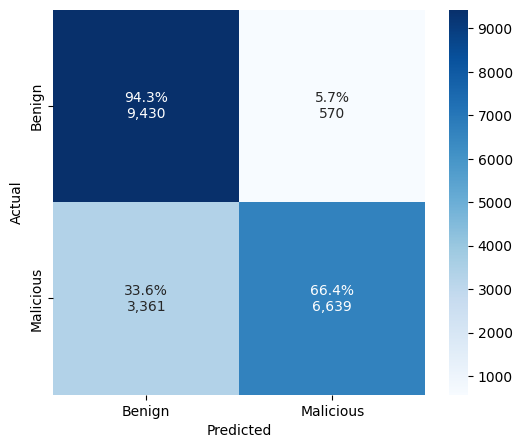

SEED: 7
Evaluation Metrics for trial 1
Threshold:            0.0001
Recall:               0.6639
Precision:            0.9209
F1-score:             0.7716
AUC (PR Curve):       0.8878
AUROC (ROC Curve):    0.8519

Seed=17, Trial=1
cfg: ViTAutoencoderConfig(input_mode='flat_1d', packet_shape=(1, 48), seq_len=48, patch_size=4, in_chans=1, embed_dim=384, latent_dim=32, depth=6, decoder_depth=2, num_heads=12, mlp_ratio=3.0, dropout=0.1, drop_path_rate=0.1, use_cls_token=True, device='cuda')
Batch input shape: (64, 1, 48)
cfg.input_mode: flat_1d
cfg.in_chans: 1
cfg.seq_len: 48
cfg.patch_size: 4
[Info] Unfreezing decoder block 0
[Info] Unfreezing decoder block 1
[Info] Unfreezing encoder block 5
Trainable params:
   encoder.5.norm1.weight
   encoder.5.norm1.bias
   encoder.5.attn.in_proj_weight
   encoder.5.attn.in_proj_bias
   encoder.5.attn.out_proj.weight
   encoder.5.attn.out_proj.bias
   encoder.5.norm2.weight
   encoder.5.norm2.bias
   encoder.5.mlp.fc1.weight
   encoder.5.mlp.fc1.bias

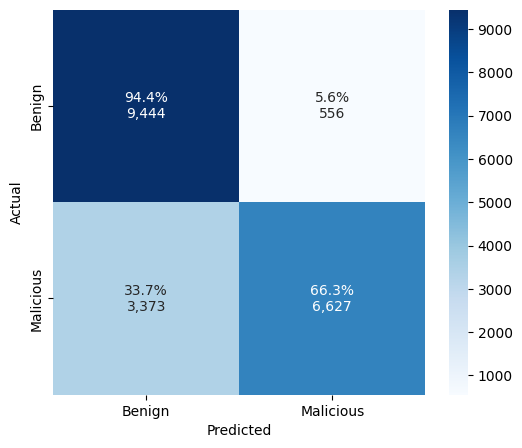

SEED: 17
Evaluation Metrics for trial 1
Threshold:            0.0001
Recall:               0.6627
Precision:            0.9226
F1-score:             0.7713
AUC (PR Curve):       0.8876
AUROC (ROC Curve):    0.8519

Seed=27, Trial=1
cfg: ViTAutoencoderConfig(input_mode='flat_1d', packet_shape=(1, 48), seq_len=48, patch_size=4, in_chans=1, embed_dim=384, latent_dim=32, depth=6, decoder_depth=2, num_heads=12, mlp_ratio=3.0, dropout=0.1, drop_path_rate=0.1, use_cls_token=True, device='cuda')
Batch input shape: (64, 1, 48)
cfg.input_mode: flat_1d
cfg.in_chans: 1
cfg.seq_len: 48
cfg.patch_size: 4
[Info] Unfreezing decoder block 0
[Info] Unfreezing decoder block 1
[Info] Unfreezing encoder block 5
Trainable params:
   encoder.5.norm1.weight
   encoder.5.norm1.bias
   encoder.5.attn.in_proj_weight
   encoder.5.attn.in_proj_bias
   encoder.5.attn.out_proj.weight
   encoder.5.attn.out_proj.bias
   encoder.5.norm2.weight
   encoder.5.norm2.bias
   encoder.5.mlp.fc1.weight
   encoder.5.mlp.fc1.bia

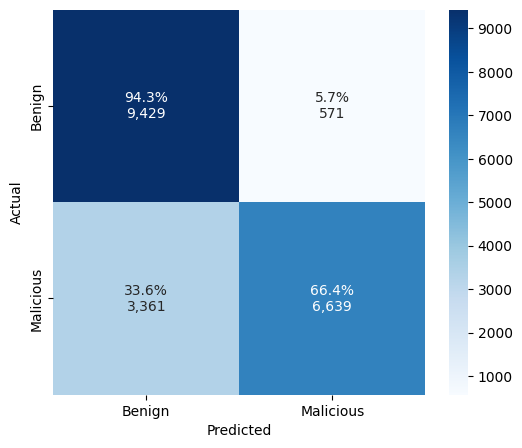

SEED: 27
Evaluation Metrics for trial 1
Threshold:            0.0001
Recall:               0.6639
Precision:            0.9208
F1-score:             0.7715
AUC (PR Curve):       0.8880
AUROC (ROC Curve):    0.8526

Seed=37, Trial=1
cfg: ViTAutoencoderConfig(input_mode='flat_1d', packet_shape=(1, 48), seq_len=48, patch_size=4, in_chans=1, embed_dim=384, latent_dim=32, depth=6, decoder_depth=2, num_heads=12, mlp_ratio=3.0, dropout=0.1, drop_path_rate=0.1, use_cls_token=True, device='cuda')
Batch input shape: (64, 1, 48)
cfg.input_mode: flat_1d
cfg.in_chans: 1
cfg.seq_len: 48
cfg.patch_size: 4
[Info] Unfreezing decoder block 0
[Info] Unfreezing decoder block 1
[Info] Unfreezing encoder block 5
Trainable params:
   encoder.5.norm1.weight
   encoder.5.norm1.bias
   encoder.5.attn.in_proj_weight
   encoder.5.attn.in_proj_bias
   encoder.5.attn.out_proj.weight
   encoder.5.attn.out_proj.bias
   encoder.5.norm2.weight
   encoder.5.norm2.bias
   encoder.5.mlp.fc1.weight
   encoder.5.mlp.fc1.bia

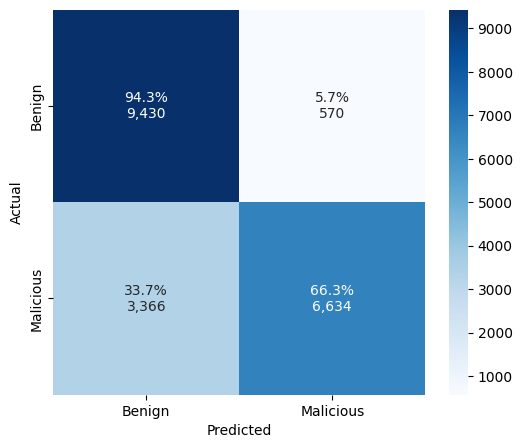

SEED: 37
Evaluation Metrics for trial 1
Threshold:            0.0001
Recall:               0.6634
Precision:            0.9209
F1-score:             0.7712
AUC (PR Curve):       0.8869
AUROC (ROC Curve):    0.8505

Seed=47, Trial=1
cfg: ViTAutoencoderConfig(input_mode='flat_1d', packet_shape=(1, 48), seq_len=48, patch_size=4, in_chans=1, embed_dim=384, latent_dim=32, depth=6, decoder_depth=2, num_heads=12, mlp_ratio=3.0, dropout=0.1, drop_path_rate=0.1, use_cls_token=True, device='cuda')
Batch input shape: (64, 1, 48)
cfg.input_mode: flat_1d
cfg.in_chans: 1
cfg.seq_len: 48
cfg.patch_size: 4
[Info] Unfreezing decoder block 0
[Info] Unfreezing decoder block 1
[Info] Unfreezing encoder block 5
Trainable params:
   encoder.5.norm1.weight
   encoder.5.norm1.bias
   encoder.5.attn.in_proj_weight
   encoder.5.attn.in_proj_bias
   encoder.5.attn.out_proj.weight
   encoder.5.attn.out_proj.bias
   encoder.5.norm2.weight
   encoder.5.norm2.bias
   encoder.5.mlp.fc1.weight
   encoder.5.mlp.fc1.bia

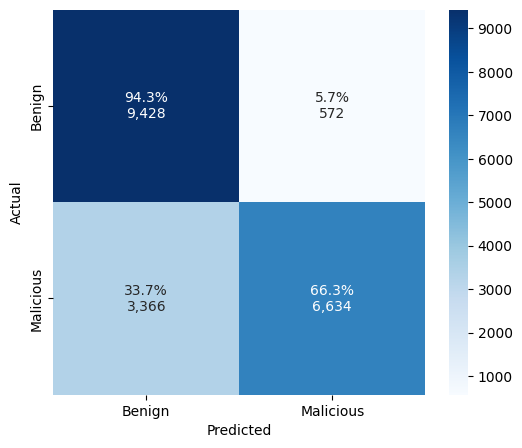

SEED: 47
Evaluation Metrics for trial 1
Threshold:            0.0001
Recall:               0.6634
Precision:            0.9206
F1-score:             0.7711
AUC (PR Curve):       0.8869
AUROC (ROC Curve):    0.8506
Saved fine-tune results to: ./results_AEViT_tabular_parquet_2018/AEViT/optuna/models/ft_700000_new/fine_tune_results.csv


In [3]:
# ============================================================
# Fine-tune pretrained tabular AE-ViT
# ============================================================

rows = []

FT_EPOCHS = 3
FT_LR = 5e-7
FT_WEIGHT_DECAY = 0.0
PATIENCE = 2

NUM_DECODER_BLOCKS_TO_UNFREEZE = 2
NUM_ENCODER_BLOCKS_TO_UNFREEZE = 1
UNFREEZE_BASE_MODULES = ["patch_head", "decoder_norm", "bottleneck"]

ft_save_dir = f"{PRETRAIN_ROOT}/models/ft_{TRAIN_TARGET_SIZE}_new"
os.makedirs(ft_save_dir, exist_ok=True)

final_csv = os.path.join(ft_save_dir, "fine_tune_results.csv")

all_idx = np.arange(len(train_subset))
train_idx, val_idx = train_test_split(
    all_idx,
    test_size=0.2,
    random_state=SPLIT_SEED,
    shuffle=True,
)

seed_time = {}

for run_seed in SEEDS:
    set_global_seed(run_seed)
    worker_init_fn = make_worker(run_seed)
    g = torch.Generator()
    g.manual_seed(run_seed)

    seed_ft_accum = 0.0

    for _, trial_row in top_trials.iterrows():

        trial_number = int(trial_row["number"])
        bs = int(trial_row["params_batch_size"])

        embed_dim = int(trial_row["params_embed_dim"])
        head_dim = int(trial_row["params_head_dim"])
        latent_dim = int(trial_row["params_latent_dim"])
        depth = int(trial_row["params_depth"])
        decoder_depth = int(trial_row["params_decoder_depth"])

        if embed_dim % head_dim != 0:
            raise ValueError(f"embed_dim={embed_dim} cannot be divided by head_dim={head_dim}")

        num_heads = embed_dim // head_dim

        cfg = ViTAutoencoderConfig(
            input_mode=INPUT_MODE,
            packet_shape=PACKET_SHAPE,
            patch_size=PATCH_SIZE,
            embed_dim=embed_dim,
            latent_dim=latent_dim,
            depth=depth,
            decoder_depth=decoder_depth,
            num_heads=num_heads,
            mlp_ratio=3.0,
            dropout=0.1,
            drop_path_rate=0.1,
        )

        print("\n" + "=" * 80)
        print(f"Seed={run_seed}, Trial={trial_number}")
        print("cfg:", cfg)
        print("=" * 80)

        train_loader = DataLoader(
            Subset(train_subset, train_idx),
            batch_size=bs,
            shuffle=True,
            num_workers=2,
            pin_memory=True,
            worker_init_fn=worker_init_fn,
            generator=g,
        )

        val_loader = DataLoader(
            Subset(train_subset, val_idx),
            batch_size=bs,
            shuffle=False,
            num_workers=2,
            pin_memory=True,
            worker_init_fn=worker_init_fn,
            generator=g,
        )

        test_loader = DataLoader(
            test_subset,
            batch_size=bs,
            shuffle=False,
            num_workers=2,
            pin_memory=True,
            worker_init_fn=worker_init_fn,
            generator=g,
        )

        xb, yb = next(iter(train_loader))
        print("Batch input shape:", tuple(xb.shape))
        print("cfg.input_mode:", cfg.input_mode)
        print("cfg.in_chans:", cfg.in_chans)
        print("cfg.seq_len:", cfg.seq_len)
        print("cfg.patch_size:", cfg.patch_size)

        model = build_model(cfg)
        model = model.to(cfg.device)

        model_path = os.path.join(model_dir, f"AE_trial_{trial_number}.pt")
        ckpt = torch.load(model_path, map_location=cfg.device)
        load_state_dict_exact_or_matching(
            model,
            ckpt,
            cfg,
            allow_partial=ALLOW_PARTIAL_CHECKPOINT_LOAD,
        )

        # ====================================================
        # Freeze all parameters first
        # ====================================================
        for p in model.parameters():
            p.requires_grad = False

        # ====================================================
        # Unfreeze base reconstruction modules
        # ====================================================
        for module_name in UNFREEZE_BASE_MODULES:
            if hasattr(model, module_name):
                module = getattr(model, module_name)
                for p in module.parameters():
                    p.requires_grad = True
            else:
                print(f"[Warning] model has no module named: {module_name}")

        # ====================================================
        # Unfreeze last N decoder blocks
        # ====================================================
        if hasattr(model, "decoder"):
            total_blocks = len(model.decoder)
            if NUM_DECODER_BLOCKS_TO_UNFREEZE > total_blocks:
                raise ValueError(
                    f"NUM_DECODER_BLOCKS_TO_UNFREEZE={NUM_DECODER_BLOCKS_TO_UNFREEZE} "
                    f"> decoder total_blocks={total_blocks}"
                )

            for i in range(total_blocks - NUM_DECODER_BLOCKS_TO_UNFREEZE, total_blocks):
                print(f"[Info] Unfreezing decoder block {i}")
                for p in model.decoder[i].parameters():
                    p.requires_grad = True
        else:
            print("[Warning] model has no module named: decoder")

        # ====================================================
        # Unfreeze last N encoder blocks
        # ====================================================
        if hasattr(model, "encoder"):
            total_blocks = len(model.encoder)
            if NUM_ENCODER_BLOCKS_TO_UNFREEZE > total_blocks:
                raise ValueError(
                    f"NUM_ENCODER_BLOCKS_TO_UNFREEZE={NUM_ENCODER_BLOCKS_TO_UNFREEZE} "
                    f"> encoder total_blocks={total_blocks}"
                )

            for i in range(total_blocks - NUM_ENCODER_BLOCKS_TO_UNFREEZE, total_blocks):
                print(f"[Info] Unfreezing encoder block {i}")
                for p in model.encoder[i].parameters():
                    p.requires_grad = True
        else:
            print("[Warning] model has no module named: encoder")

        trainable_params = [n for n, p in model.named_parameters() if p.requires_grad]
        print("Trainable params:")
        for n in trainable_params:
            print("  ", n)

        trainable_parameters = [p for p in model.parameters() if p.requires_grad]
        if len(trainable_parameters) == 0:
            raise ValueError("No trainable parameters found after unfreezing.")

        opt = torch.optim.AdamW(
            trainable_parameters,
            lr=FT_LR,
            weight_decay=FT_WEIGHT_DECAY,
        )

        scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
            opt,
            T_max=FT_EPOCHS * len(train_loader),
        )

        best = float("inf")
        best_state = None
        bad = 0

        t0 = time.perf_counter()

        for epoch in range(FT_EPOCHS):
            meters = pretrain_one_epoch(model, train_loader, opt, cfg, scheduler=scheduler)
            val = validate(model, val_loader, cfg)

            print(f"[{epoch:03d}] MSE_Loss={meters['loss']:.6f}  Val_MSE={val['val_loss']:.6f}")

            if val["val_loss"] < best - 1e-6:
                best = val["val_loss"]
                bad = 0
                best_state = {
                    k: v.detach().cpu().clone()
                    for k, v in model.state_dict().items()
                }
            else:
                bad += 1
                if bad >= PATIENCE:
                    print(f"Early stopping at epoch {epoch}")
                    break

        seed_ft_accum += time.perf_counter() - t0

        if best_state is not None:
            model.load_state_dict(best_state)

        ft_ckpt = {
            "state_dict": {
                k: v.detach().cpu().clone()
                for k, v in model.state_dict().items()
            },
            "cfg": model.cfg.__dict__,
            "trial_number": trial_number,
            "seed": run_seed,
            "input_mode": INPUT_MODE,
            "packet_shape": PACKET_SHAPE,
            "patch_size": PATCH_SIZE,
            "source_checkpoint": model_path,
        }

        ft_model_path = os.path.join(
            ft_save_dir,
            f"AE_ft_tabular_trial_{trial_number}_seed_{run_seed}.pt",
        )
        torch.save(ft_ckpt, ft_model_path)

        model.eval()
        scores = []
        y_true = []

        with torch.no_grad():
            for x, y in test_loader:
                x = x.to(cfg.device, non_blocking=True)
                recon, _ = model(x)

                # anomaly score = reconstruction MSE per sample
                s = (recon - x).pow(2).flatten(1).mean(1)

                scores.append(s.detach().cpu().numpy())
                y_true.append(y.numpy())

        test_score = np.concatenate(scores, axis=0)
        y_true = np.concatenate(y_true, axis=0)

        print("[DEBUG] y_eval distribution:", Counter(y_true.tolist()))

        test_metrics = evaluate_results(y_true, test_score)
        print(f"[DEBUG] AUROC: {test_metrics['auroc']:.4f}, F1: {test_metrics['f1']:.4f}")

        threshold = test_metrics["threshold"]
        results = evaluate_test_data(y_true, test_score, threshold)

        plot_confusion_matrix(y_true, test_score, threshold, pos_label=-1)

        metrics_dict = {
            "tgt_train_target_size": TRAIN_TARGET_SIZE,
            "seed": run_seed,
            "trial_number": trial_number,

            "threshold": results["threshold"],

            "TP": results["TP"],
            "FP": results["FP"],
            "TN": results["TN"],
            "FN": results["FN"],

            "TPR": results["TPR"],
            "FPR": results["FPR"],

            "precision": results["precision"],
            "recall": results["recall"],
            "f1": results["f1"],

            "au_precision_recall": results["au_precision_recall"],
            "auroc": results["auroc"],

            "ft_save_dir": ft_save_dir,
        }

          
        
        rows.append(metrics_dict)

        print(f"SEED: {run_seed}")
        print(f"Evaluation Metrics for trial {trial_number}")
        print(f"Threshold:            {threshold:.4f}")
        print(f"Recall:               {results['recall']:.4f}")
        print(f"Precision:            {results['precision']:.4f}")
        print(f"F1-score:             {results['f1']:.4f}")
        print(f"AUC (PR Curve):       {results['au_precision_recall']:.4f}")
        print(f"AUROC (ROC Curve):    {results['auroc']:.4f}")

        del model, train_loader, val_loader, test_loader
        torch.cuda.empty_cache()

    seed_time[run_seed] = seed_ft_accum

df_out = pd.DataFrame(rows)
df_out["seed_ft_total_sec"] = df_out["seed"].map(seed_time)
df_out["seed_ft_total_hms"] = df_out["seed_ft_total_sec"].apply(_fmt_hms)
df_out.to_csv(final_csv, index=False)

print("Saved fine-tune results to:", final_csv)

In [4]:
# ============================================================
# Summary
# ============================================================

df_out = pd.DataFrame(rows)

summary = (
    df_out.groupby("trial_number")[["precision", "recall", "f1", "auroc", "au_precision_recall"]]
          .agg(["mean", "std"])
          .round(4)
)

print("\n=== Seed-wise summary per trial: mean ± std ===")
print(summary)

summary_csv = final_csv.replace(".csv", "_summary.csv")
summary.to_csv(summary_csv)

print("Saved summary to:", summary_csv)


=== Seed-wise summary per trial: mean ± std ===
             precision          recall              f1           auroc  \
                  mean     std    mean     std    mean     std    mean   
trial_number                                                             
1               0.9212  0.0008  0.6635  0.0005  0.7714  0.0002  0.8515   

                     au_precision_recall          
                 std                mean     std  
trial_number                                      
1             0.0009              0.8874  0.0005  
Saved summary to: ./results_AEViT_tabular_parquet_2018/AEViT/optuna/models/ft_700000_new/fine_tune_results_summary.csv
